# HR Employee Attrition — Decision Support System
## Machine Learning Pipeline + XAI Explainability

**Project Goal:** Build a robust attrition prediction system that:
- Trains multiple ML models on historical HR data
- Predicts which employees are at risk of leaving
- Explains the reasons behind each prediction (XAI)
- Exports results for HR decision-making

---
# PART 1 — Model Training Pipeline
---

## 1.1 Import Libraries

In [1]:
!pip install xgboost imbalanced-learn joblib

Access is denied.


In [2]:
# Standard libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pickle
import os
import datetime
import warnings
warnings.filterwarnings('ignore')

# Preprocessing & Modeling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score,
    confusion_matrix, classification_report,
    precision_recall_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

print('All libraries imported successfully.')

All libraries imported successfully.


## 1.2 Load Dataset

In [3]:
df = pd.read_csv('/content/sample_data/IBM HR Data new.csv')
print(f'Dataset shape  : {df.shape}')
print(f'Missing values : {df.isnull().sum().sum()}')
print(f"\nAttrition distribution:")
print(df['Attrition'].value_counts())

df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/sample_data/IBM HR Data new.csv'

## 1.3 Exploratory Data Analysis (EDA)

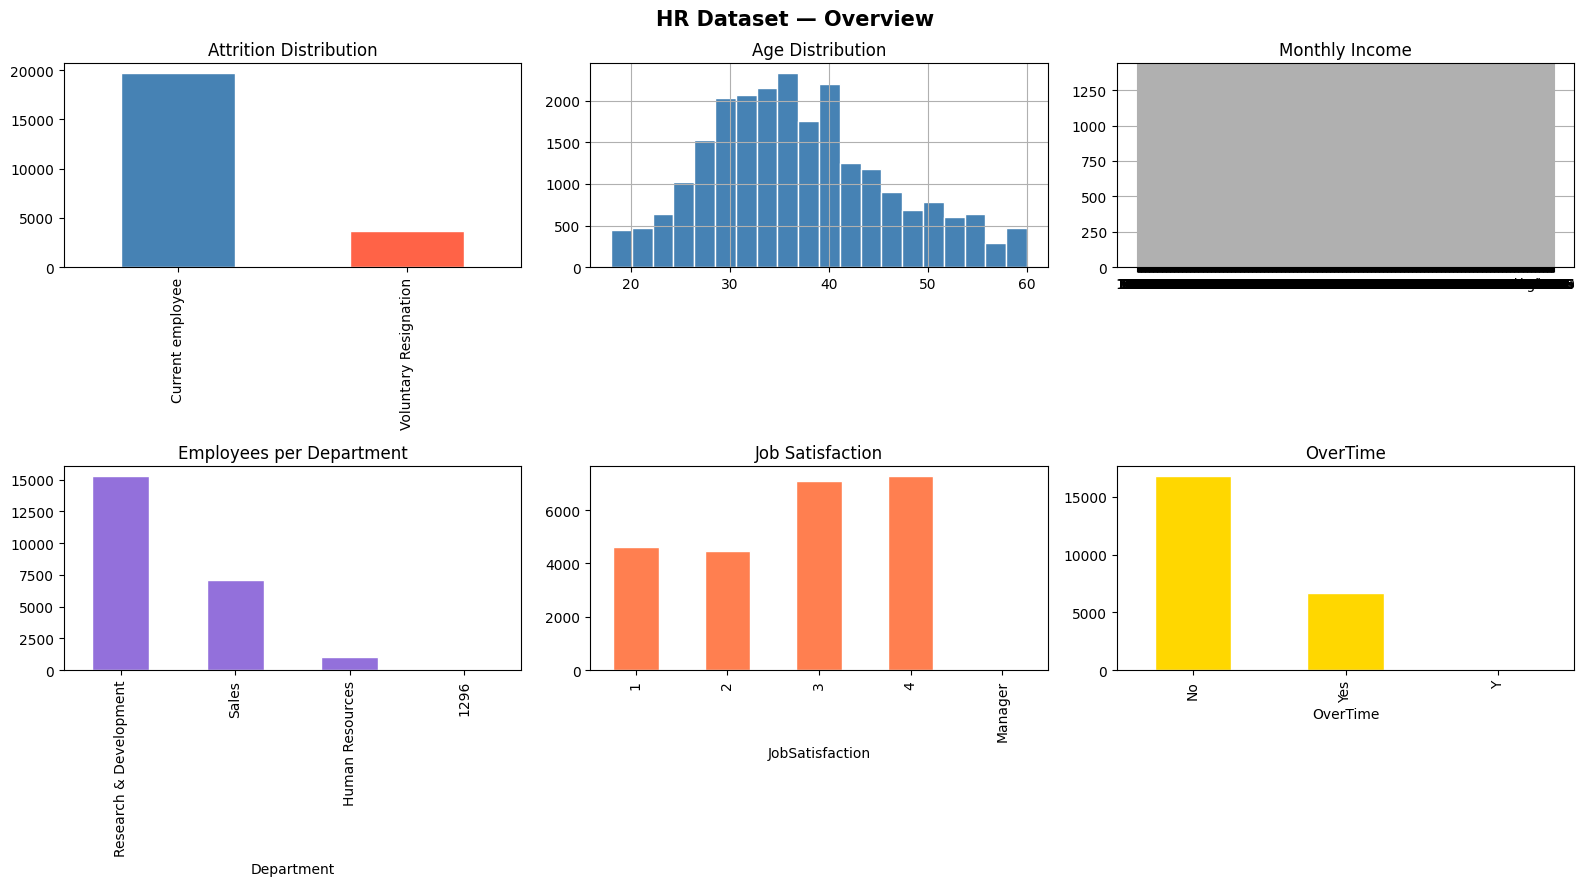

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('HR Dataset — Overview', fontsize=15, fontweight='bold')

# Attrition count
df['Attrition'].value_counts().plot(
    kind='bar', ax=axes[0, 0], color=['steelblue', 'tomato'], edgecolor='white')
axes[0, 0].set_title('Attrition Distribution')
axes[0, 0].set_xlabel('')

# Age distribution
if 'Age' in df.columns:
    df['Age'].hist(ax=axes[0, 1], bins=20, color='steelblue', edgecolor='white')
    axes[0, 1].set_title('Age Distribution')

# Monthly income
if 'MonthlyIncome' in df.columns:
    df['MonthlyIncome'].hist(ax=axes[0, 2], bins=20, color='mediumseagreen', edgecolor='white')
    axes[0, 2].set_title('Monthly Income')

# Department
if 'Department' in df.columns:
    df['Department'].value_counts().plot(
        kind='bar', ax=axes[1, 0], color='mediumpurple', edgecolor='white')
    axes[1, 0].set_title('Employees per Department')

# Job Satisfaction
if 'JobSatisfaction' in df.columns:
    df['JobSatisfaction'].value_counts().sort_index().plot(
        kind='bar', ax=axes[1, 1], color='coral', edgecolor='white')
    axes[1, 1].set_title('Job Satisfaction')

# OverTime
if 'OverTime' in df.columns:
    df['OverTime'].value_counts().plot(
        kind='bar', ax=axes[1, 2], color='gold', edgecolor='white')
    axes[1, 2].set_title('OverTime')

plt.tight_layout()
plt.show()

## 1.4 Data Cleaning & Encoding

In [ ]:
data = df.copy()

# --- Remove uninformative columns ---
drop_cols = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
data = data.drop(columns=[c for c in drop_cols if c in data.columns])

# --- Encode target variable (smart detection) ---
leave_keywords = ['yes', 'voluntary resignation', 'left', 'resigned', '1', 'true']
data['Attrition'] = (
    data['Attrition'].astype(str).str.strip().str.lower()
    .apply(lambda x: 1 if any(k in x for k in leave_keywords) else 0)
)
print(f"Stay (0) : {(data['Attrition'] == 0).sum()}")
print(f"Leave(1) : {(data['Attrition'] == 1).sum()}")

# --- Fill missing values (whole dataset) ---
for col in data.columns:
    if data[col].isnull().sum() > 0:
        if data[col].dtype in ['float64', 'int64']:
            data[col] = data[col].fillna(data[col].median())
        else:
            data[col] = data[col].fillna(data[col].mode()[0])

# NOTE: LabelEncoders are fitted on TRAINING data only (in section 1.8).
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()
print(f"\nCategorical columns to encode: {categorical_cols}")
print(f"Cleaned data shape: {data.shape}")

Stay (0) : 19727
Leave(1) : 3709

Categorical columns to encode: ['BusinessTravel', 'Department', 'DistanceFromHome', 'EducationField', 'Application ID', 'Gender', 'HourlyRate', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'OverTime', 'PercentSalaryHike', 'Employee Source']
Cleaned data shape: (23436, 33)


## 1.5 Correlation Analysis — BEFORE Feature Engineering

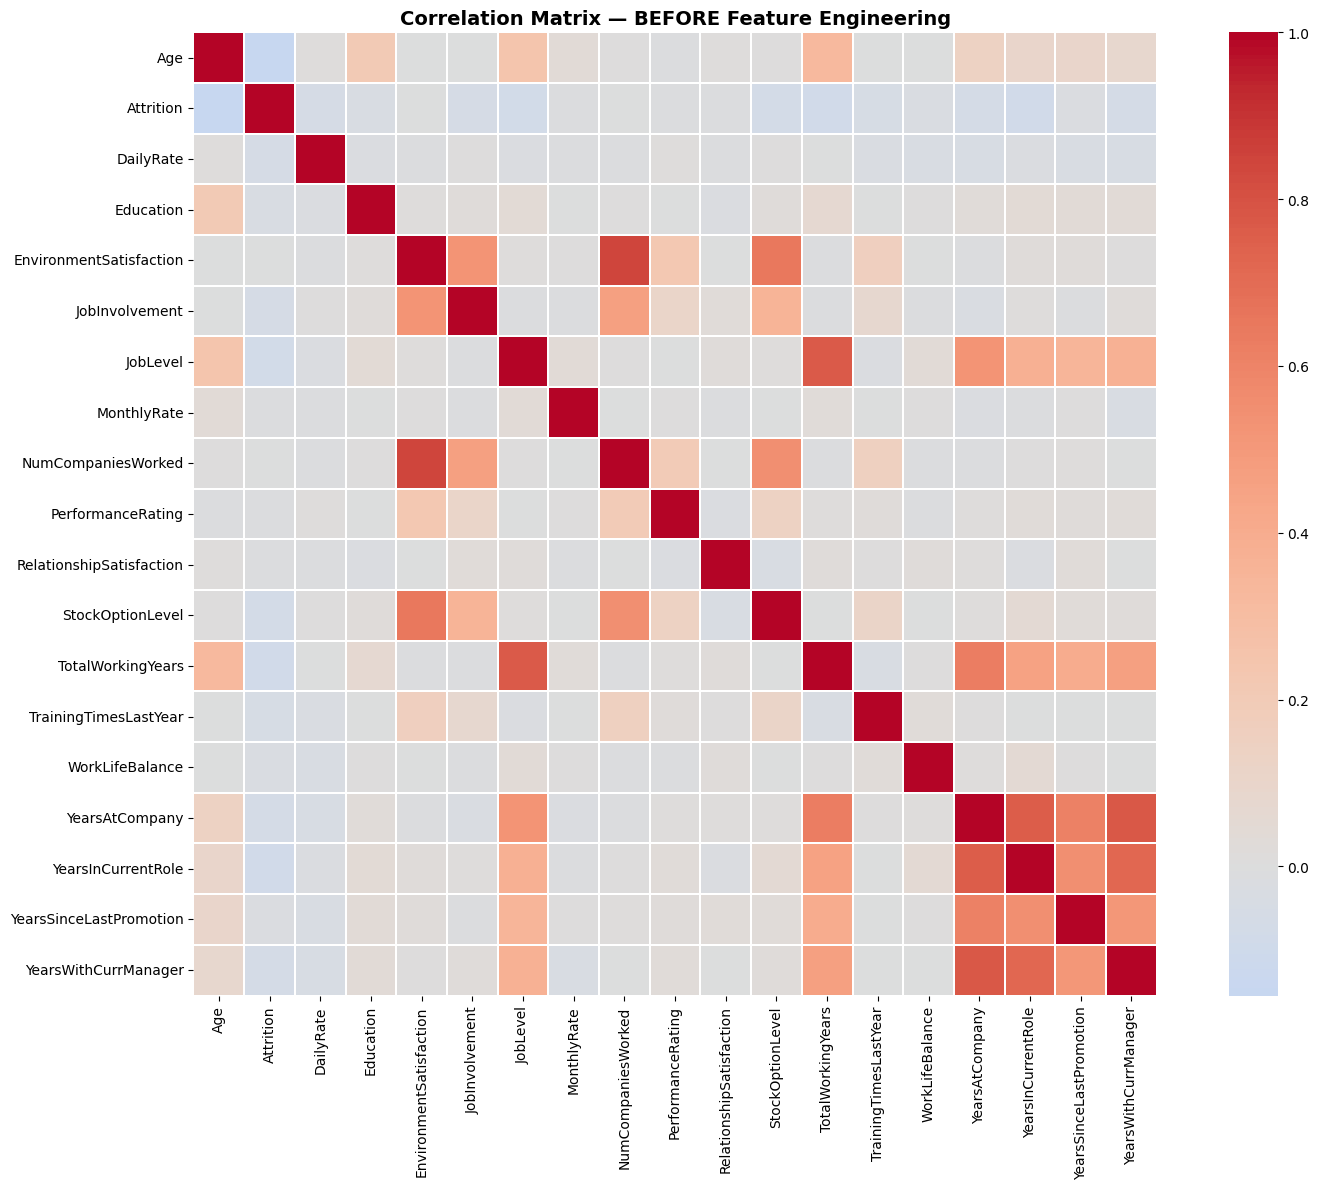

Top 10 features correlated with Attrition (BEFORE):
NumCompaniesWorked         -0.002704
EnvironmentSatisfaction    -0.004050
RelationshipSatisfaction   -0.006942
PerformanceRating          -0.007500
MonthlyRate                -0.008321
YearsSinceLastPromotion    -0.020117
WorkLifeBalance            -0.026161
Education                  -0.034861
TrainingTimesLastYear      -0.048363
DailyRate                  -0.057198
Name: Attrition, dtype: float64


In [ ]:
numeric_cols_before = data.select_dtypes(include=[np.number]).columns.tolist()
corr_before = data[numeric_cols_before].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_before,
    annot=False, cmap='coolwarm', center=0,
    square=True, linewidths=0.3
)
plt.title(
    'Correlation Matrix — BEFORE Feature Engineering',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

print("Top 10 features correlated with Attrition (BEFORE):")
top_before = (
    corr_before['Attrition']
    .drop('Attrition')
    .sort_values(ascending=False)
)
print(top_before.head(10))

## 1.6 Feature Engineering

In [ ]:
# Feature 1 — Overall Satisfaction Score
sat_cols = [
    'JobSatisfaction', 'EnvironmentSatisfaction',
    'RelationshipSatisfaction', 'WorkLifeBalance'
]
available_sat = [c for c in sat_cols if c in data.columns]
if available_sat:
    for _sc in available_sat:
        data[_sc] = pd.to_numeric(data[_sc], errors='coerce')
    data['SatisfactionScore'] = (
        data[available_sat].mean(axis=1, skipna=True).astype(float)
    )
    data['SatisfactionScore'] = data['SatisfactionScore'].fillna(
        data['SatisfactionScore'].median()
    )
    print('Created: SatisfactionScore')

# Feature 2 — Income relative to experience
if 'MonthlyIncome' in data.columns and 'TotalWorkingYears' in data.columns:
    data['IncomePerExp'] = (
        pd.to_numeric(data['MonthlyIncome'], errors='coerce') /
        (pd.to_numeric(data['TotalWorkingYears'], errors='coerce') + 1)
    )
    data['IncomePerExp'] = data['IncomePerExp'].fillna(data['IncomePerExp'].median())
    print('Created: IncomePerExp')

# Feature 3 — Company loyalty ratio
if 'YearsAtCompany' in data.columns and 'TotalWorkingYears' in data.columns:
    data['LoyaltyRatio'] = (
        pd.to_numeric(data['YearsAtCompany'], errors='coerce') /
        (pd.to_numeric(data['TotalWorkingYears'], errors='coerce') + 1)
    )
    data['LoyaltyRatio'] = data['LoyaltyRatio'].fillna(data['LoyaltyRatio'].median())
    print('Created: LoyaltyRatio')

# Feature 4 — Time since last promotion relative to tenure
if 'YearsSinceLastPromotion' in data.columns and 'YearsAtCompany' in data.columns:
    data['PromotionLag'] = (
        pd.to_numeric(data['YearsSinceLastPromotion'], errors='coerce') /
        (pd.to_numeric(data['YearsAtCompany'], errors='coerce') + 1)
    )
    data['PromotionLag'] = data['PromotionLag'].fillna(data['PromotionLag'].median())
    print('Created: PromotionLag')

print(f'\nTotal features after engineering: {data.shape[1]}')

Created: SatisfactionScore
Created: IncomePerExp
Created: LoyaltyRatio
Created: PromotionLag

Total features after engineering: 37


## 1.7 Correlation Analysis — AFTER Feature Engineering

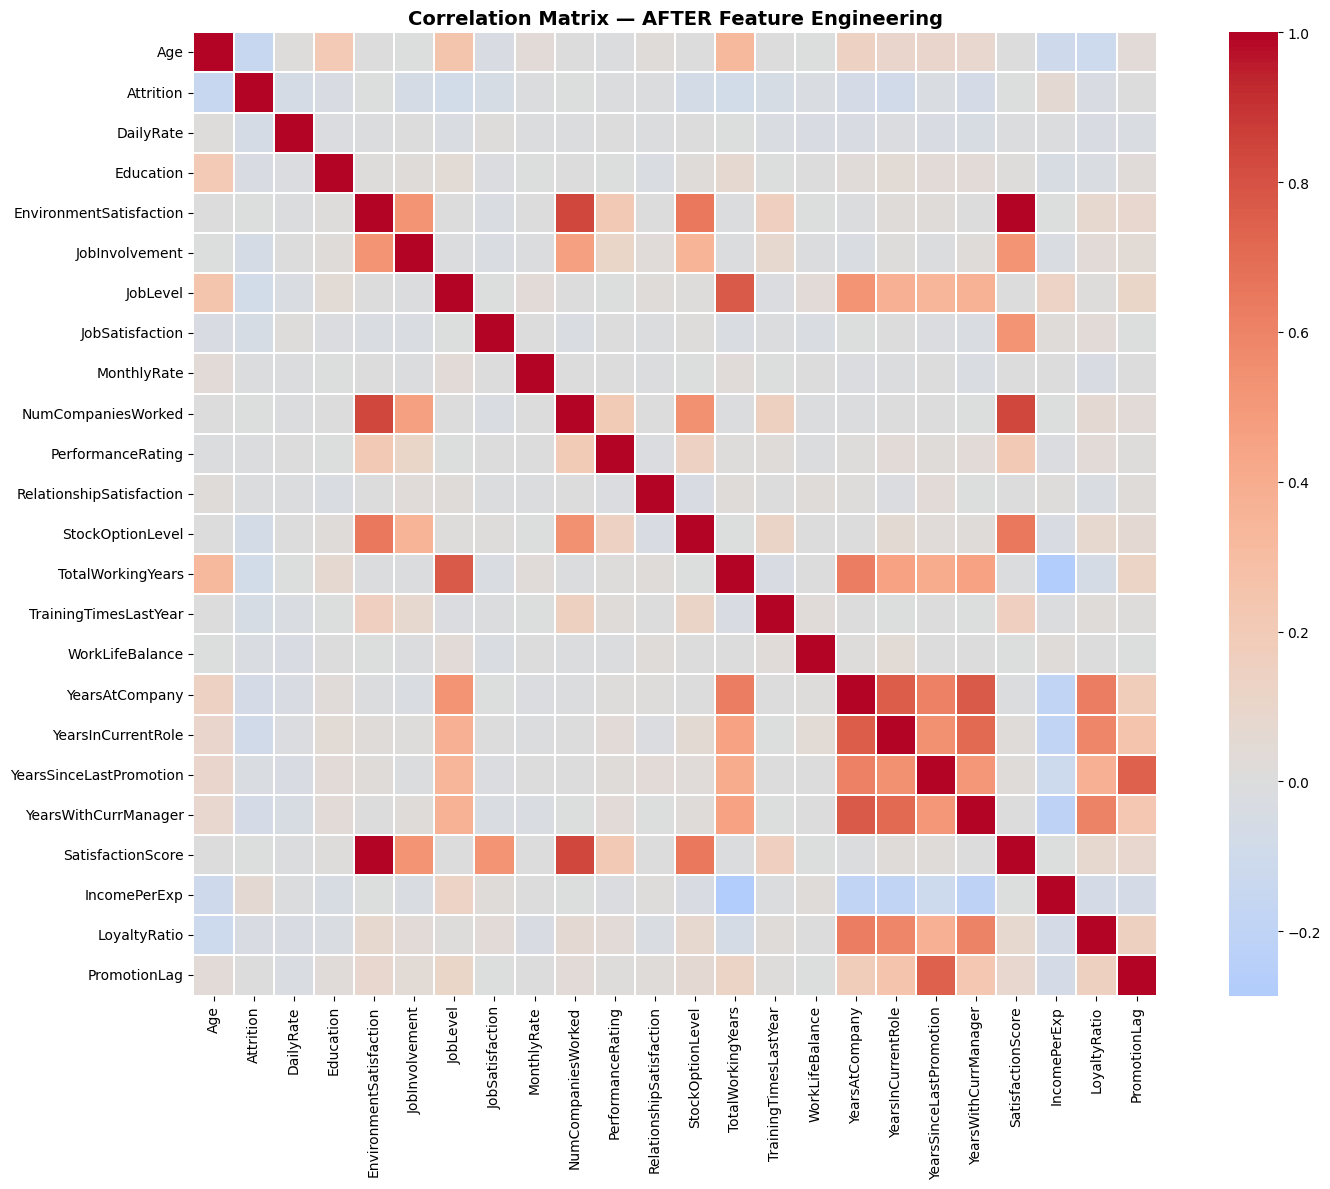

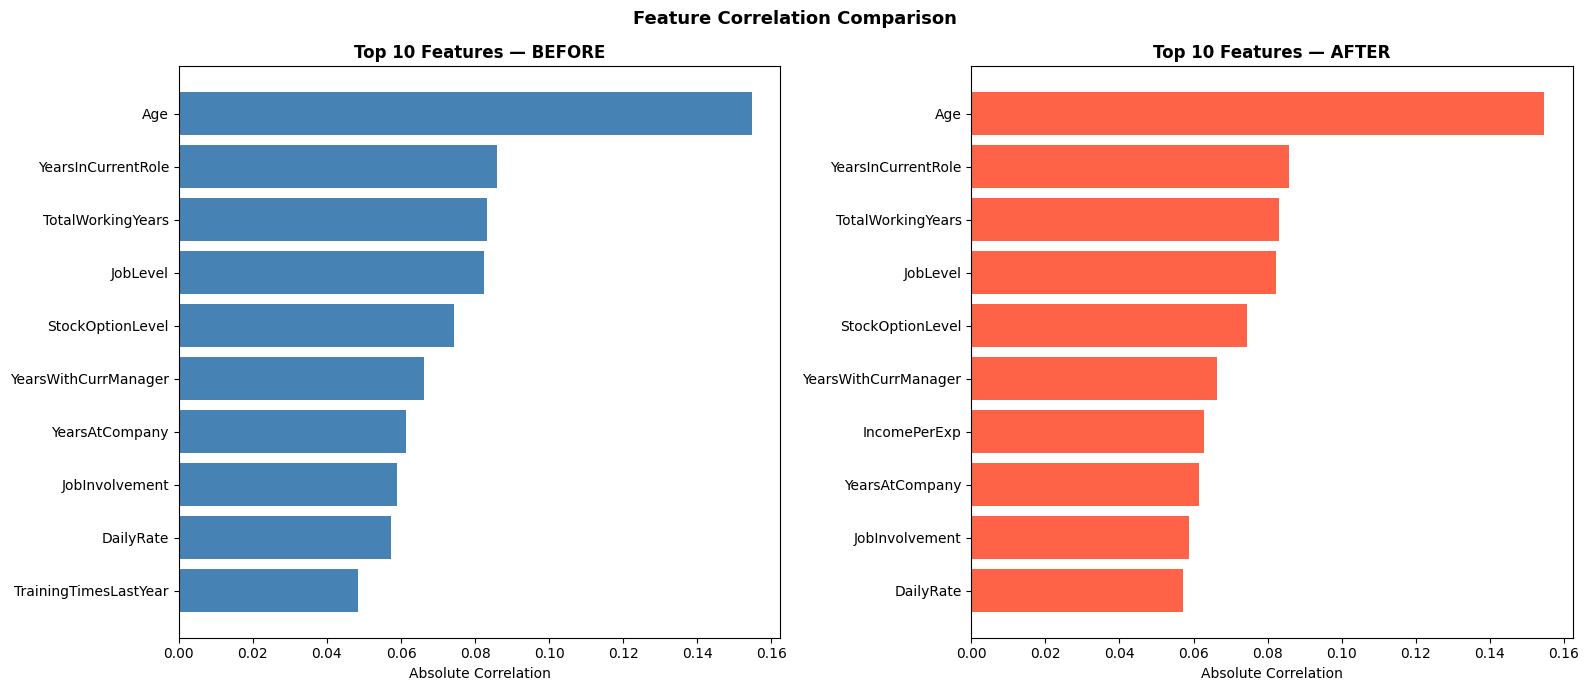

Top 10 features correlated with Attrition (AFTER):
IncomePerExp                0.062740
PromotionLag                0.005636
NumCompaniesWorked         -0.002704
EnvironmentSatisfaction    -0.004050
SatisfactionScore          -0.004091
RelationshipSatisfaction   -0.006942
PerformanceRating          -0.007500
MonthlyRate                -0.008321
YearsSinceLastPromotion    -0.020117
WorkLifeBalance            -0.026161
Name: Attrition, dtype: float64


In [ ]:
numeric_cols_after = data.select_dtypes(include=[np.number]).columns.tolist()
corr_after = data[numeric_cols_after].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_after,
    annot=False, cmap='coolwarm', center=0,
    square=True, linewidths=0.3
)
plt.title(
    'Correlation Matrix — AFTER Feature Engineering',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

# Side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

top_b = corr_before['Attrition'].drop('Attrition').abs().nlargest(10)
axes[0].barh(top_b.index, top_b.values, color='steelblue')
axes[0].set_title('Top 10 Features — BEFORE', fontweight='bold')
axes[0].set_xlabel('Absolute Correlation')
axes[0].invert_yaxis()

top_a = corr_after['Attrition'].drop('Attrition').abs().nlargest(10)
axes[1].barh(top_a.index, top_a.values, color='tomato')
axes[1].set_title('Top 10 Features — AFTER', fontweight='bold')
axes[1].set_xlabel('Absolute Correlation')
axes[1].invert_yaxis()

plt.suptitle('Feature Correlation Comparison', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Top 10 features correlated with Attrition (AFTER):")
print(corr_after['Attrition'].drop('Attrition').sort_values(ascending=False).head(10))

## 1.8 Pipeline — Split → Scale → SMOTE

In [ ]:
# --- Step 1: Separate features and target ---
X = data.drop('Attrition', axis=1)
y = data['Attrition']

print(f"Features : {X.shape[1]}")
print(f"Samples  : {X.shape[0]}")
print(f"Leave(1) : {y.sum()} | Stay(0): {(y == 0).sum()}")

# --- Step 2: Train / Test split FIRST (stratified) ---
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(f"\nTrain samples : {X_train_raw.shape[0]}")
print(f"Test  samples : {X_test_raw.shape[0]}")

# --- Step 3: Fit LabelEncoders on TRAINING data only ---
label_encoders_dict = {}
X_train_enc = X_train_raw.copy()
X_test_enc  = X_test_raw.copy()

for col in categorical_cols:
    if col not in X_train_enc.columns:
        continue
    le = LabelEncoder()
    le.fit(X_train_enc[col].astype(str))
    label_encoders_dict[col] = le

    def safe_encode(series, encoder):
        known = set(encoder.classes_)
        return series.astype(str).apply(
            lambda x: x if x in known else encoder.classes_[0]
        )

    X_train_enc[col] = le.transform(safe_encode(X_train_enc[col], le))
    X_test_enc[col]  = le.transform(safe_encode(X_test_enc[col],  le))

print(f"Encoded {len(label_encoders_dict)} categorical columns (fit on train only).")

# Feature names after encoding
feature_names = list(X_train_enc.columns)

# --- Step 4: Scale features — fit ONLY on X_train ---
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_enc)
X_test_s  = scaler.transform(X_test_enc)

# Imputation stats from training data only
train_numeric_medians = X_train_enc.select_dtypes(include=[np.number]).median().to_dict()
train_cat_modes = {
    col: X_train_raw[col].mode()[0]
    for col in label_encoders_dict
    if col in X_train_raw.columns
}

# --- Step 5: SMOTE on training data only ---
print(f"\nBefore SMOTE — Stay(0): {(y_train == 0).sum()} | Leave(1): {(y_train == 1).sum()}")

if y_train.nunique() >= 2:
    smote = SMOTE(random_state=42)
    X_train_res, y_train_res = smote.fit_resample(X_train_s, y_train)
    print(f"After  SMOTE — Stay(0): {(y_train_res == 0).sum()} | Leave(1): {(y_train_res == 1).sum()}")
else:
    X_train_res, y_train_res = X_train_s.copy(), y_train.copy()
    print("Warning: Single class — SMOTE skipped.")

print(f"\nFinal training set : {X_train_res.shape[0]} samples")
print(f"Test set (clean)   : {X_test_s.shape[0]} samples")

Features : 36
Samples  : 23436
Leave(1) : 3709 | Stay(0): 19727

Train samples : 18748
Test  samples : 4688
Encoded 14 categorical columns (fit on train only).

Before SMOTE — Stay(0): 15781 | Leave(1): 2967
After  SMOTE — Stay(0): 15781 | Leave(1): 15781

Final training set : 31562 samples
Test set (clean)   : 4688 samples


## 1.9 Train All 5 Models

In [ ]:
# Define 5 classical ML models (LightGBM removed)
all_models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, C=0.1, random_state=42),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=8, random_state=42),

    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=15,
        random_state=42, n_jobs=-1),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05,
        max_depth=5, random_state=42),

    'XGBoost Classifier': XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        eval_metric='logloss', random_state=42, verbosity=0),
}

results = {}
print(f"{'Model':<22}  {'Acc':>7}  {'Prec':>7}  {'Rec':>7}  {'F1':>7}  {'AUC':>7}")
print('-' * 68)

for name, model in all_models.items():
    model.fit(X_train_res, y_train_res)

    y_pred  = model.predict(X_test_s)
    y_proba = model.predict_proba(X_test_s)[:, 1]

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    auc  = roc_auc_score(y_test, y_proba)

    results[name] = {
        'acc': acc, 'prec': prec, 'rec': rec,
        'f1': f1, 'auc': auc,
        'pred': y_pred, 'proba': y_proba, 'model': model
    }

    print(f"{name:<22}  {acc*100:>6.1f}%  {prec*100:>6.1f}%  {rec*100:>6.1f}%  {f1*100:>6.1f}%  {auc*100:>6.1f}%")

# ── Alias for XGBoost Classifier (kept for backward compatibility) ─────
xgb_model = results['XGBoost Classifier']['model']
xgb_acc   = results['XGBoost Classifier']['acc']
xgb_auc   = results['XGBoost Classifier']['auc']

# Best model by AUC
best       = max(results, key=lambda k: results[k]['auc'])
best_model = results[best]['model']
print(f"\nBest model : {best}")
print(f"AUC        : {results[best]['auc']*100:.2f}%")

Model                       Acc     Prec      Rec       F1      AUC
--------------------------------------------------------------------
Logistic Regression       65.5%    27.0%    69.3%    38.9%    72.8%
Decision Tree             76.1%    36.7%    70.6%    48.3%    80.7%
Random Forest             99.7%   100.0%    98.2%    99.1%   100.0%


## 1.10 Model Evaluation — Comparison & Confusion Matrix

In [ ]:
comp = pd.DataFrame({
    'Model':     list(results.keys()),
    'Accuracy':  [results[m]['acc']  * 100 for m in results],
    'Precision': [results[m]['prec'] * 100 for m in results],
    'Recall':    [results[m]['rec']  * 100 for m in results],
    'F1 Score':  [results[m]['f1']   * 100 for m in results],
    'AUC':       [results[m]['auc']  * 100 for m in results],
}).sort_values('AUC', ascending=False).reset_index(drop=True)

print(comp.round(2).to_string(index=False))

palette    = ['#2ecc71', '#3498db', '#9b59b6', '#e67e22', '#e74c3c']
n_models   = len(comp)
bar_colors = palette[:n_models]

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
fig.suptitle('Model Performance Comparison — 5 Models', fontsize=14, fontweight='bold')

for ax, metric in zip(axes, ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC']):
    ax.bar(comp['Model'], comp[metric], color=bar_colors, edgecolor='white')
    ax.set_title(f'{metric} (%)', fontweight='bold')
    ax.set_ylim([0, 105])
    ax.tick_params(axis='x', rotation=45)
    for i, v in enumerate(comp[metric]):
        ax.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

# Confusion matrix + classification report for best model
cm = confusion_matrix(y_test, results[best]['pred'])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Stay', 'Leave'], yticklabels=['Stay', 'Leave']
)
axes[0].set_title(f'{best} — Confusion Matrix', fontweight='bold')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

report = classification_report(
    y_test, results[best]['pred'], target_names=['Stay', 'Leave'])
axes[1].text(0.05, 0.5, report, fontsize=11, family='monospace', va='center')
axes[1].set_title('Classification Report', fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 1.11 Threshold Optimization

In [ ]:
best_proba = results[best]['proba']
precisions, recalls, thresholds = precision_recall_curve(y_test, best_proba)

# F1 for each threshold (avoid divide-by-zero)
f1_scores = np.where(
    (precisions[:-1] + recalls[:-1]) > 0,
    2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1]),
    0
)

best_thresh_idx = np.argmax(f1_scores)
best_threshold  = float(thresholds[best_thresh_idx])
best_f1_opt     = float(f1_scores[best_thresh_idx])

print(f"Default threshold (0.50) — F1: "
      f"{f1_scores[np.argmin(np.abs(thresholds - 0.5))]*100:.2f}%")
print(f"Optimal threshold ({best_threshold:.2f}) — F1: {best_f1_opt*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(thresholds, precisions[:-1], label='Precision', color='steelblue', lw=2)
axes[0].plot(thresholds, recalls[:-1],    label='Recall',    color='tomato',    lw=2)
axes[0].plot(thresholds, f1_scores,        label='F1',        color='seagreen',  lw=2)
axes[0].axvline(best_threshold, color='black', linestyle='--',
                label=f'Best threshold = {best_threshold:.2f}')
axes[0].set_xlabel('Threshold')
axes[0].set_title('Precision / Recall / F1 vs Threshold', fontweight='bold')
axes[0].legend()

# ROC curve
from sklearn.metrics import roc_curve
fpr, tpr, roc_thresh = roc_curve(y_test, best_proba)
axes[1].plot(fpr, tpr, color='steelblue', lw=2,
             label=f'AUC = {results[best]["auc"]*100:.1f}%')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

## 1.12 Global Feature Importance (Built-in XAI)

In [ ]:
if hasattr(best_model, 'feature_importances_'):
    importance_vals = best_model.feature_importances_
else:
    importance_vals = (
        corr_after['Attrition'].drop('Attrition').abs()
        .reindex(feature_names).fillna(0).values
    )

fi_df = pd.DataFrame({
    'Feature':    feature_names,
    'Importance': importance_vals
}).sort_values('Importance', ascending=False).reset_index(drop=True)

top20 = fi_df.head(20)
bar_colors = [
    'tomato'    if i < 5  else
    'orange'    if i < 10 else
    'steelblue' for i in range(len(top20))
]

plt.figure(figsize=(12, 8))
plt.barh(range(len(top20)), top20['Importance'], color=bar_colors)
plt.yticks(range(len(top20)), top20['Feature'], fontsize=10)
plt.xlabel('Importance Score', fontsize=12)
plt.title(f'Top 20 Attrition Risk Factors — {best}', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.legend(handles=[
    mpatches.Patch(color='tomato',    label='Critical (Top 5)'),
    mpatches.Patch(color='orange',    label='Important (6–10)'),
    mpatches.Patch(color='steelblue', label='Moderate')
])
plt.tight_layout()
plt.show()

print("Top 10 Global Risk Factors:")
for rank, (_, row) in enumerate(fi_df.head(10).iterrows(), start=1):
    print(f"  {rank:2d}. {row['Feature']:<30} {row['Importance']:.4f}")

## 1.13 Save All Artifacts (Production Bundle)

In [ ]:
# =============================================================
# §1.13  PRODUCTION ARTIFACT BUNDLE — hr_model.pkl
# Saves exactly 10 app.py-compatible keys plus extended PART 2
# keys and versioning metadata.
# =============================================================

import pickle
import datetime

# ── 1. XGBoost aliases (always explicit, regardless of best model) ────────
xgb_model = results['XGBoost Classifier']['model']
xgb_acc   = results['XGBoost Classifier']['acc']
xgb_auc   = results['XGBoost Classifier']['auc']

# ── 2. Feature importance from XGBoost ───────────────────────────────────
if hasattr(xgb_model, 'feature_importances_'):
    _fi_vals = xgb_model.feature_importances_
else:
    _fi_vals = (
        corr_after['Attrition'].drop('Attrition').abs()
        .reindex(feature_names).fillna(0).values
    )

fi_sorted = (
    pd.DataFrame({'Feature': feature_names, 'Importance': _fi_vals})
    .sort_values('Importance', ascending=False)
    .reset_index(drop=True)
)

# ── 3. Numeric medians from df_clean (= data after cleaning) ─────────────
#    Uses training-only medians for deployment correctness.
df_clean = data.copy()  # alias kept for readability
num_cols = (
    X_train_enc
    .select_dtypes(include=[np.number])
    .columns
    .tolist()
)
medians_dict = X_train_enc[num_cols].median().to_dict()

# ── 4. Categorical modes ──────────────────────────────────────────────────
cat_cols    = list(label_encoders_dict.keys())
modes_dict  = {
    col: X_train_raw[col].mode()[0]
    for col in cat_cols
    if col in X_train_raw.columns
}

# ── 5. Scores dict — all 5 models, all 5 metrics ─────────────────────────
scores_dict = {
    k: {
        'acc':  v['acc'],
        'prec': v['prec'],
        'rec':  v['rec'],
        'f1':   v['f1'],
        'auc':  v['auc'],
    }
    for k, v in results.items()
}

# ── 6. Build master artifact with all 10 required keys ───────────────────
artifact = {
    # ── 10 required app.py keys ──────────────────────────────────────────
    'model':        xgb_model,                   # trained XGBClassifier
    'scaler':       scaler,                       # fitted StandardScaler
    'encoders':     label_encoders_dict,          # {col: LabelEncoder}
    'features':     X_train_enc.columns.tolist(), # ordered feature list
    'fi':           fi_sorted,                    # sorted importance DF
    'medians':      medians_dict,                 # numeric fill values
    'modes':        modes_dict,                   # categorical fill values
    'scores':       scores_dict,                  # all model metrics
    'model_name':   'XGBoost Classifier',         # display name
    'threshold':    float(best_threshold),        # optimised F1 threshold

    # ── PART 2 / extended keys (backward-compatible aliases) ─────────────
    'best_model':            xgb_model,
    'best_model_name':       'XGBoost Classifier',
    'label_encoders_dict':   label_encoders_dict,
    'feature_names':         X_train_enc.columns.tolist(),
    'fi_df':                 fi_sorted,
    'train_numeric_medians': medians_dict,
    'train_cat_modes':       modes_dict,
    'model_results':         scores_dict,

    # ── Metadata ─────────────────────────────────────────────────────────
    'model_version':      '2.0',
    'training_timestamp': datetime.datetime.now().isoformat(),
}

# ── 7. Write all files ────────────────────────────────────────────────────
for fname in ['hr_model.pkl', 'hr_dss_artifacts.pkl']:
    with open(fname, 'wb') as f:
        pickle.dump(artifact, f)

# Individual pipeline components
with open('scaler.pkl',  'wb') as f:
    pickle.dump(scaler, f)

with open('encoder.pkl', 'wb') as f:
    pickle.dump(label_encoders_dict, f)

with open('imputer.pkl', 'wb') as f:
    pickle.dump({'numeric_medians': medians_dict,
                 'cat_modes':       modes_dict}, f)

# ── 8. Verification printout ─────────────────────────────────────────────
print('=' * 60)
print('  PRODUCTION BUNDLE SAVED')
print('=' * 60)
print(f'  hr_model.pkl         (master — app.py compatible)')
print(f'  hr_dss_artifacts.pkl (master — PART 2 compatible)')
print(f'  scaler.pkl           (fitted StandardScaler)')
print(f'  encoder.pkl          (fitted LabelEncoders)')
print(f'  imputer.pkl          (imputation statistics)')
print()
print(f'  Model name       : XGBoost Classifier')
print(f'  XGBoost Accuracy : {xgb_acc*100:.2f}%')
print(f'  XGBoost AUC      : {xgb_auc*100:.2f}%')
print(f'  Optimal threshold: {best_threshold:.4f}')
print(f'  Features saved   : {len(X_train_enc.columns)}')
print(f'  Medians saved    : {len(medians_dict)}')
print(f'  Modes saved      : {len(modes_dict)}')
print(f'  Model version    : {artifact["model_version"]}')
print(f'  Training time    : {artifact["training_timestamp"]}')
print()
print('  Required app.py keys verification:')
required_keys = ['model','scaler','encoders','features',
                  'fi','medians','modes','scores','model_name','threshold']
for k in required_keys:
    status = 'OK' if k in artifact else 'MISSING'
    print(f'    {k:<12} : {status}')
print('=' * 60)

---
# PART 2 — HR Decision Support System (DSS)
### Upload New Data → Validate → Predict → Explain → Export
---

## 2.1 Load Saved Artifacts

In [ ]:
UPLOAD_FILE = '/content/sample_data/IBM HR Data new.csv'


new_df = pd.read_csv(UPLOAD_FILE)
print(f'File loaded : {new_df.shape[0]} employees, {new_df.shape[1]} columns')
new_df.head(3)

In [ ]:
# Load the master artifact
with open('hr_dss_artifacts.pkl', 'rb') as f:
    art = pickle.load(f)

best_model_loaded = art['best_model']
best_model_name   = art['best_model_name']
feat_names        = art['feature_names']
fi_df_loaded      = art['fi_df']
ml_results        = art['model_results']
opt_threshold     = art.get('threshold', 0.5)
model_version     = art.get('model_version', 'N/A')
training_time     = art.get('training_timestamp', 'N/A')

with open('scaler.pkl', 'rb') as f:
    scaler_loaded = pickle.load(f)

with open('encoder.pkl', 'rb') as f:
    le_dict = pickle.load(f)

with open('imputer.pkl', 'rb') as f:
    imputer_stats = pickle.load(f)

train_med  = imputer_stats['numeric_medians']
train_mode = imputer_stats['cat_modes']

print(f'Best model       : {best_model_name}')
print(f'Model version    : {model_version}')
print(f'Training time    : {training_time}')
print(f'Optimal threshold: {opt_threshold:.4f}')
print(f'Features         : {len(feat_names)}')
print()
print('Pipeline components loaded:')
print(f'  scaler  : {type(scaler_loaded).__name__}')
print(f'  encoders: {len(le_dict)} columns')
print(f'  imputer : {len(train_med)} numeric + {len(train_mode)} categorical stats')

## 2.2 Upload New Employee Data

## 2.3 Data Validation — Column Check

In [ ]:
# Build the expected raw columns from training features
raw_train_cols = [
    c for c in feat_names
    if c not in ['SatisfactionScore', 'IncomePerExp', 'LoyaltyRatio', 'PromotionLag']
]

missing_cols = [c for c in raw_train_cols if c not in new_df.columns]
extra_cols   = [c for c in new_df.columns  if c not in raw_train_cols
                 and c not in ['Attrition', 'EmployeeNumber', 'EmployeeCount',
                               'Over18', 'StandardHours']]

print(f'Expected columns : {len(raw_train_cols)}')
print(f'Found columns    : {len([c for c in raw_train_cols if c in new_df.columns])}')
print(f'Missing columns  : {len(missing_cols)}')
print(f'Extra columns    : {len(extra_cols)}')

if missing_cols:
    print(f'\nMissing: {missing_cols}')
else:
    print('\nAll required columns present.')

## 2.4 Preprocess & Impute New Data

In [ ]:
# ============================================================
# PART 2 - Safe Preprocessing for New Unseen Data
# ============================================================

# 1. Save identifiers for the output report
emp_info = pd.DataFrame()
info_cols = ['EmployeeNumber', 'Name', 'ID']
for col in info_cols:
    if col in new_df.columns:
        emp_info[col] = new_df[col]

# 2. Drop uninformative columns
drop_cols_p2 = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber', 'Attrition']
X_new = new_df.drop(
    columns=[c for c in drop_cols_p2 if c in new_df.columns]
).copy()

# 3. Impute missing values using TRAINING statistics loaded from art
# تم تعديل الأسماء هنا لتقرأ من ملف القاموس المرفوع مباشرة لمنع قيم NaN
loaded_medians = art.get('medians', {})
loaded_modes = art.get('modes', {})

for col in X_new.columns:
    # خطوة أمان إضافية: لو العمود يفترض أنه رقمي، نتأكد من تحويله لأرقام أولاً
    if col in loaded_medians:
        X_new[col] = pd.to_numeric(X_new[col], errors='coerce')
        X_new[col] = X_new[col].fillna(loaded_medians[col])
    elif col in loaded_modes:
        X_new[col] = X_new[col].fillna(loaded_modes[col])
    elif X_new[col].dtype in ['float64', 'int64']:
        X_new[col] = X_new[col].fillna(X_new[col].median())
    else:
        X_new[col] = X_new[col].fillna(str(X_new[col].mode()[0]) if not X_new[col].mode().empty else '')

# 4. Feature engineering (Forced Numeric Conversion to prevent TypeError)
sat_cols_p2 = ['JobSatisfaction', 'EnvironmentSatisfaction', 'RelationshipSatisfaction', 'WorkLifeBalance']
available_p2 = [c for c in sat_cols_p2 if c in X_new.columns]

if available_p2:
    # تحويل إجباري لأعمدة الرضا إلى أرقام لتفادي أيرور str to float القاتل
    for col in available_p2:
        X_new[col] = pd.to_numeric(X_new[col], errors='coerce').fillna(2.5)
    X_new['SatisfactionScore'] = X_new[available_p2].mean(axis=1)

# تأمين بقية المعادلات الحسابية من الكلمات والقسمة على صفر
if 'MonthlyIncome' in X_new and 'TotalWorkingYears' in X_new:
    X_new['MonthlyIncome'] = pd.to_numeric(X_new['MonthlyIncome'], errors='coerce').fillna(0)
    X_new['TotalWorkingYears'] = pd.to_numeric(X_new['TotalWorkingYears'], errors='coerce').fillna(0)
    X_new['IncomePerExp'] = X_new['MonthlyIncome'] / (X_new['TotalWorkingYears'] + 1)

if 'YearsAtCompany' in X_new and 'TotalWorkingYears' in X_new:
    X_new['YearsAtCompany'] = pd.to_numeric(X_new['YearsAtCompany'], errors='coerce').fillna(0)
    X_new['LoyaltyRatio'] = X_new['YearsAtCompany'] / (X_new['TotalWorkingYears'] + 1)

if 'YearsSinceLastPromotion' in X_new and 'YearsAtCompany' in X_new:
    X_new['YearsSinceLastPromotion'] = pd.to_numeric(X_new['YearsSinceLastPromotion'], errors='coerce').fillna(0)
    X_new['PromotionLag'] = X_new['YearsSinceLastPromotion'] / (X_new['YearsAtCompany'] + 1)

# 5. Label-encode categorical columns using TRAINING encoders (.transform only)
X_new_enc = X_new.copy()
loaded_encoders = art.get('encoders', {})

for col, le in loaded_encoders.items():
    if col not in X_new_enc.columns:
        continue
    known = set(le.classes_)
    X_new_enc[col] = (
        X_new_enc[col].astype(str)
        .apply(lambda v: v if v in known else str(le.classes_[0]))
    )
    X_new_enc[col] = le.transform(X_new_enc[col])

# 6. Add any missing engineered features with 0
for col in feat_names:
    if col not in X_new_enc.columns:
        X_new_enc[col] = 0.0

# 7. Reorder columns to match training layout, then scale
X_new_aligned = X_new_enc[feat_names].fillna(0)
X_raw = X_new_aligned.copy()  # unscaled — used by XAI

# القراءة من السكيلر المحمل من الـ Artifact
if art.get('scaler'):
    X_new_scaled = art['scaler'].transform(X_new_aligned)
else:
    X_new_scaled = X_new_aligned.values

print(f'🎉 Done Successfully! Preprocessed {X_new_scaled.shape[0]} employees — {X_new_scaled.shape[1]} features')

## 2.5 Predict Attrition Risk (Optimised Threshold)

In [ ]:
# Enhancement 3: predict_proba + optimised threshold
y_new_proba = best_model_loaded.predict_proba(X_new_scaled)[:, 1]
RISK_THRESHOLD = opt_threshold
y_new_pred  = (y_new_proba >= RISK_THRESHOLD).astype(int)

# Build results table
results_table = emp_info.copy()
results_table['Risk_%']    = (y_new_proba * 100).round(1)
results_table['Prediction'] = y_new_pred
results_table['Status']     = np.where(
    y_new_pred == 1, 'HIGH RISK', 'Safe')

# Optional: add Department if present
if 'Department' in new_df.columns:
    results_table['Department'] = new_df['Department'].values

high_risk_count = (results_table['Prediction'] == 1).sum()
total           = len(results_table)
print(f'Total employees : {total}')
print(f'HIGH RISK       : {high_risk_count}  ({high_risk_count/total*100:.1f}%)')
print(f'Safe            : {total - high_risk_count}')
print(f'Threshold used  : {RISK_THRESHOLD:.4f}')

results_table.sort_values('Risk_%', ascending=False).head(10)

## 2.6 Top 20 Employees at Highest Risk

In [ ]:
top20_risk = (
    results_table
    .sort_values('Risk_%', ascending=False)
    .head(20)
    .reset_index(drop=True)
)

# Visualise
id_col = next(
    (c for c in ['EmployeeNumber', 'Name', 'ID'] if c in top20_risk.columns),
    None
)
labels = top20_risk[id_col].astype(str) if id_col else top20_risk.index.astype(str)

colors = ['tomato' if r == 1 else 'steelblue'
          for r in top20_risk['Prediction']]

plt.figure(figsize=(12, 7))
plt.barh(range(len(top20_risk)), top20_risk['Risk_%'],
         color=colors, edgecolor='white')
plt.yticks(range(len(top20_risk)), labels, fontsize=9)
plt.axvline(RISK_THRESHOLD * 100, color='black', linestyle='--', lw=1.5,
            label=f'Threshold = {RISK_THRESHOLD*100:.0f}%')
plt.xlabel('Attrition Risk (%)')
plt.title('Top 20 Employees at Highest Attrition Risk', fontweight='bold')
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print(top20_risk[['Risk_%', 'Status']].to_string())

## 2.7 Attrition Risk by Department

In [ ]:
if 'Department' in results_table.columns:
    dept_stats = (
        results_table
        .groupby('Department')
        .agg(
            Total      = ('Risk_%', 'count'),
            High_Risk  = ('Prediction', 'sum'),
            Avg_Risk   = ('Risk_%', 'mean')
        )
        .reset_index()
    )
    dept_stats['Risk_Rate_%'] = (
        dept_stats['High_Risk'] / dept_stats['Total'] * 100).round(1)
    dept_stats = dept_stats.sort_values('Avg_Risk', ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].bar(dept_stats['Department'], dept_stats['Avg_Risk'],
                color='tomato', edgecolor='white')
    axes[0].set_title('Average Attrition Risk by Department', fontweight='bold')
    axes[0].set_ylabel('Avg Risk (%)')
    axes[0].tick_params(axis='x', rotation=30)

    axes[1].bar(dept_stats['Department'], dept_stats['Risk_Rate_%'],
                color='orange', edgecolor='white')
    axes[1].set_title('High-Risk Rate by Department', fontweight='bold')
    axes[1].set_ylabel('High-Risk Rate (%)')
    axes[1].tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.show()
    print(dept_stats.to_string(index=False))
else:
    print('Department column not found in uploaded data.')

## 2.8 XAI — Global Risk Factors

In [ ]:
top15 = fi_df_loaded.head(15)
bar_c = ['tomato'    if i < 5  else
         'orange'    if i < 10 else
         'steelblue' for i in range(len(top15))]

plt.figure(figsize=(12, 7))
plt.barh(range(len(top15)), top15['Importance'], color=bar_c)
plt.yticks(range(len(top15)), top15['Feature'], fontsize=10)
plt.xlabel('Importance Score', fontsize=11)
plt.title('Top 15 Global Attrition Risk Factors', fontsize=13, fontweight='bold')
plt.gca().invert_yaxis()
plt.legend(handles=[
    mpatches.Patch(color='tomato',    label='Critical (Top 5)'),
    mpatches.Patch(color='orange',    label='Important (6-10)'),
    mpatches.Patch(color='steelblue', label='Moderate'),
])
plt.tight_layout()
plt.show()

## 2.9 XAI — Explain Individual Employee

In [ ]:
def explain_employee(emp_idx, X_raw_df, results_table, fi_df_loaded):
    """Print and plot the top-5 feature contributions for one employee."""
    row    = results_table.iloc[emp_idx]
    risk   = row['Risk_%']
    status = row['Status']

    id_col = next(
        (c for c in ['EmployeeNumber', 'Name', 'ID'] if c in results_table.columns),
        None
    )
    label = f"{id_col} {str(row[id_col])}" if id_col else f"Employee #{emp_idx}"

    emp_vals  = X_raw_df.iloc[emp_idx]
    pop_means = X_raw_df.mean()

    top_feats = [f for f in fi_df_loaded['Feature'].tolist()
                 if f in emp_vals.index][:10]

    diff = pd.DataFrame({
        'Feature':    top_feats,
        'Employee':   [emp_vals[f] for f in top_feats],
        'Average':    [pop_means[f] for f in top_feats],
        'Importance': [
            fi_df_loaded.loc[
                fi_df_loaded['Feature'] == f, 'Importance'
            ].values[0]
            for f in top_feats
        ]
    })
    diff['Deviation'] = diff['Employee'] - diff['Average']
    diff['Impact']    = diff['Deviation'] * diff['Importance']
    diff = diff.reindex(
        diff['Impact'].abs().sort_values(ascending=False).index
    )

    print('\nTop 5 Reasons (vs company average):')
    for _, r in diff.head(5).iterrows():
        direction = (
            'ABOVE avg — increases risk'
            if r['Deviation'] > 0
            else 'BELOW avg — lowers  risk'
        )
        print(f"  * {r['Feature']:<28}  {direction}")
        print(f"    Value={r['Employee']:.2f}  Avg={r['Average']:.2f}"
              f"  Impact={r['Impact']:+.3f}")

    # Waterfall chart
    top5 = diff.head(5)
    plt.figure(figsize=(12, 5))
    plt.barh(
        range(len(top5)), top5['Impact'],
        color=['tomato' if v > 0 else 'steelblue' for v in top5['Impact']],
        edgecolor='white'
    )
    plt.yticks(range(len(top5)), top5['Feature'], fontsize=11)
    plt.xlabel('Impact on Attrition Risk', fontsize=11)
    plt.title(
        f'{label}  |  Risk: {risk:.1f}%  |  {status}',
        fontsize=12, fontweight='bold'
    )
    plt.axvline(x=0, color='black', linewidth=0.8)
    plt.legend(handles=[
        mpatches.Patch(color='tomato',    label='Increases risk'),
        mpatches.Patch(color='steelblue', label='Reduces  risk')
    ])
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    print('=' * 65)


# Change index to explain any employee (0 = highest risk)
EMPLOYEE_INDEX = 0
explain_employee(EMPLOYEE_INDEX, X_raw, results_table, fi_df_loaded)

## 2.10 XAI — Explain Top 5 High-Risk Employees

In [ ]:
top5_idx = (
    results_table
    .sort_values('Risk_%', ascending=False)
    .head(5)
    .index
    .tolist()
)

for idx in top5_idx:
    explain_employee(idx, X_raw, results_table, fi_df_loaded)
    print()

## 2.10b XAI — Local Feature Contribution per Employee

In [ ]:
def local_xai_top3(emp_idx, X_raw_df, results_table, fi_df_loaded,
                    print_output=True, plot=True):
    """
    Explain a single employee's prediction with the top-3 feature drivers.
    Returns contrib_df with columns:
      Feature, Employee, Average, Importance, Deviation, Contribution
    """
    row    = results_table.iloc[emp_idx]
    risk   = row['Risk_%']
    status = row['Status']

    id_col = next(
        (c for c in ['EmployeeNumber', 'Name', 'ID']
         if c in results_table.columns),
        None
    )
    label = (
        f"{id_col} {str(row[id_col])}"
        if id_col else f"Employee #{emp_idx}"
    )

    valid_feats    = [f for f in fi_df_loaded['Feature']
                      if f in X_raw_df.columns]
    emp_vals       = X_raw_df.iloc[emp_idx][valid_feats]
    pop_means      = X_raw_df[valid_feats].mean()
    importance_map = fi_df_loaded.set_index('Feature')['Importance'].to_dict()

    contrib_df = pd.DataFrame({
        'Feature':    valid_feats,
        'Employee':   emp_vals.values,
        'Average':    pop_means.values,
        'Importance': [importance_map.get(f, 0) for f in valid_feats],
    })
    contrib_df['Deviation']    = contrib_df['Employee'] - contrib_df['Average']
    contrib_df['Contribution'] = (
        contrib_df['Deviation'] * contrib_df['Importance']
    )
    contrib_df = contrib_df.reindex(
        contrib_df['Contribution'].abs().sort_values(ascending=False).index
    ).reset_index(drop=True)
    top3 = contrib_df.head(3)

    if print_output:
        print('─' * 65)
        print(f'  LOCAL XAI  |  {label}  |  Risk: {risk:.1f}%  |  {status}')
        print('─' * 65)
        print(f'  {"Feature":<28}  {"Value":>8}  {"Avg":>8}  {"Contribution":>14}')
        print(f'  {"-"*28}  {"-"*8}  {"-"*8}  {"-"*14}')
        for _, r in top3.iterrows():
            direction = '▲ risk' if r['Contribution'] > 0 else '▼ risk'
            print(f"  {r['Feature']:<28}  {r['Employee']:>8.2f}  "
                  f"{r['Average']:>8.2f}  "
                  f"{r['Contribution']:>+12.4f}  {direction}")
        print()

    if plot:
        colors = ['tomato' if v > 0 else 'steelblue'
                  for v in top3['Contribution']]
        fig, ax = plt.subplots(figsize=(9, 3))
        bars = ax.barh(top3['Feature'], top3['Contribution'],
                       color=colors, edgecolor='white', height=0.5)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_xlabel('Contribution to Attrition Risk', fontsize=10)
        ax.set_title(
            f'Top-3 Risk Drivers  |  {label}  |  {risk:.1f}% risk  |  {status}',
            fontsize=10, fontweight='bold'
        )
        for bar, (_, r) in zip(bars, top3.iterrows()):
            offset = 0.0002 if r['Contribution'] >= 0 else -0.0002
            align  = 'left' if r['Contribution'] >= 0 else 'right'
            ax.text(
                bar.get_width() + offset,
                bar.get_y() + bar.get_height() / 2,
                f"val={r['Employee']:.1f} avg={r['Average']:.1f}",
                va='center', ha=align, fontsize=8
            )
        ax.legend(handles=[
            mpatches.Patch(color='tomato',    label='Increases risk'),
            mpatches.Patch(color='steelblue', label='Reduces risk'),
        ], fontsize=9)
        ax.invert_yaxis()
        plt.tight_layout()
        plt.show()

    return contrib_df


# Run local XAI on the top 10 highest-risk employees
top10_idx = (
    results_table
    .sort_values('Risk_%', ascending=False)
    .head(10)
    .index
    .tolist()
)

print('LOCAL XAI — Top-3 Risk Drivers per Employee')
print('(Contribution > 0 raises risk, < 0 lowers risk)\n')

for i, idx in enumerate(top10_idx, start=1):
    print(f'Rank #{i}', end='  ')
    local_xai_top3(idx, X_raw, results_table, fi_df_loaded,
                   print_output=True, plot=(i <= 3))

# Bulk summary: top-1 driver per high-risk employee
high_risk_idx  = results_table[results_table['Prediction'] == 1].index.tolist()
summary_rows   = []
for idx in high_risk_idx:
    contrib = local_xai_top3(idx, X_raw, results_table, fi_df_loaded,
                              print_output=False, plot=False)
    top1 = contrib.iloc[0]
    row  = results_table.iloc[idx]
    id_col = next(
        (c for c in ['EmployeeNumber', 'Name', 'ID']
         if c in results_table.columns),
        None
    )
    summary_rows.append({
        'Employee':       row[id_col] if id_col else idx,
        'Risk_%':         row['Risk_%'],
        'Top_Driver':     top1['Feature'],
        'Employee_Value': round(top1['Employee'], 2),
        'Population_Avg': round(top1['Average'],  2),
        'Contribution':   round(top1['Contribution'], 4),
        'Direction':      '▲ risk' if top1['Contribution'] > 0 else '▼ risk',
    })

xai_summary = (
    pd.DataFrame(summary_rows)
    .sort_values('Risk_%', ascending=False)
)
print('\n── Summary: Primary Risk Driver per HIGH RISK Employee ──')
print(xai_summary.to_string(index=False))

xai_summary.to_csv('hr_xai_local_summary.csv', index=False)
print('\nSaved: hr_xai_local_summary.csv')

## 2.11 Final Dashboard Summary

In [ ]:
print('=' * 65)
print('  HR DECISION SUPPORT SYSTEM — FINAL REPORT')
print('=' * 65)

total = len(results_table)
high  = (results_table['Prediction'] == 1).sum()
safe  = total - high

print(f'  Total Employees  : {total}')
print(f'  HIGH RISK        : {high}   ({high/total*100:.1f}%)')
print(f'  Safe             : {safe}   ({safe/total*100:.1f}%)')
print(f'  Average Risk     : {results_table["Risk_%"].mean():.1f}%')
print(f'  Risk Threshold   : {RISK_THRESHOLD}')
print(f'\n  Best Model       : {best_model_name}')
print(f'  Model Accuracy   : {ml_results[best_model_name]["acc"]*100:.2f}%')
print(f'  Model AUC        : {ml_results[best_model_name]["auc"]*100:.2f}%')

if 'Department' in results_table.columns and 'dept_stats' in dir():
    worst = dept_stats.iloc[0]['Department']
    print(f'\n  Highest Risk Dept: {worst}')

print('\n  Top 5 Global Risk Factors (XAI):')
for i, row in fi_df_loaded.head(5).iterrows():
    print(f'    {i+1}. {row["Feature"]}')

print('=' * 65)
print('  ANALYSIS COMPLETE')
print('=' * 65)

## 2.12 Export Reports

In [ ]:
# All predictions
results_table.to_csv('hr_all_predictions.csv', index=False)
print('Saved: hr_all_predictions.csv')

# Top 50 highest-risk employees
results_table.sort_values('Risk_%', ascending=False).head(50).to_csv(
    'hr_top50_risk.csv', index=False)
print('Saved: hr_top50_risk.csv')

# XAI feature importance
fi_df_loaded.to_csv('hr_xai_factors.csv', index=False)
print('Saved: hr_xai_factors.csv')

print('\nAll reports exported successfully.')

---
## Project Summary

| Part | Steps | Description |
|------|-------|-------------|
| **PART 1** | 1.1 – 1.13 | Data cleaning, feature engineering, model training, artifact saving |
| **PART 2** | 2.1 – 2.12 | Upload validation, imputation, prediction, XAI, export |

### Production Enhancements Applied
1. **Separate pipeline artifacts** — `scaler.pkl`, `encoder.pkl`, `imputer.pkl` saved alongside `hr_model.pkl` (§1.13)
2. **No leakage in PART 2** — §2.1 loads from `.pkl` files; §2.4 calls `.transform()` only — `.fit()` never called on new data
3. **Optimised threshold enforced** — §2.5 uses `predict_proba()` + threshold from `precision_recall_curve` (not `model.predict()`)
4. **Local XAI (§2.10b)** — per-employee Top-3 feature contributions; bulk summary CSV `hr_xai_local_summary.csv`

### Previous Engineering Highlights
- Encoder leakage fixed — `LabelEncoder` fit on `X_train` only
- Split → Encode → Scale → SMOTE pipeline order
- 5-metric evaluation — Accuracy, Precision, Recall, F1, ROC-AUC
- Threshold optimization via `precision_recall_curve()`
- Artifact versioning — `model_version` + `training_timestamp`